# Thermal Plant Disease Classification — HOG + HSV + LBP

Classifies thermal images of rice (paddy) leaves into 6 classes (BLB, Blast, healthy, hispa, leaf folder, leaf spot) using hand-crafted features and classical ML models.

**Pipeline:** download dataset from Kaggle → resize to 128×128 → extract HOG (shape) + HSV histogram (thermal colour distribution) + LBP (texture) features → standardise → train Random Forest, SVM, LightGBM, XGBoost → confusion matrices, one-vs-rest ROC curves, feature importance, summary table.

**Requirements:** a Kaggle API token (`kaggle.json`) — the first cell asks you to upload it. Runs on Google Colab.


Lütfen kaggle.json dosyasını yükleyin...


Saving kaggle.json to kaggle.json
Veri seti indiriliyor...
Dataset URL: https://www.kaggle.com/datasets/sujaradha/thermal-images-diseased-healthy-leaves-paddy
License(s): unknown
100% 44.3M/44.3M [00:01<00:00, 27.9MB/s]

Veri hazır!
Görseller işleniyor ve özellikler birleştiriliyor...
Random Forest eğitiliyor...
SVM eğitiliyor...
LightGBM eğitiliyor...


XGBoost eğitiliyor...


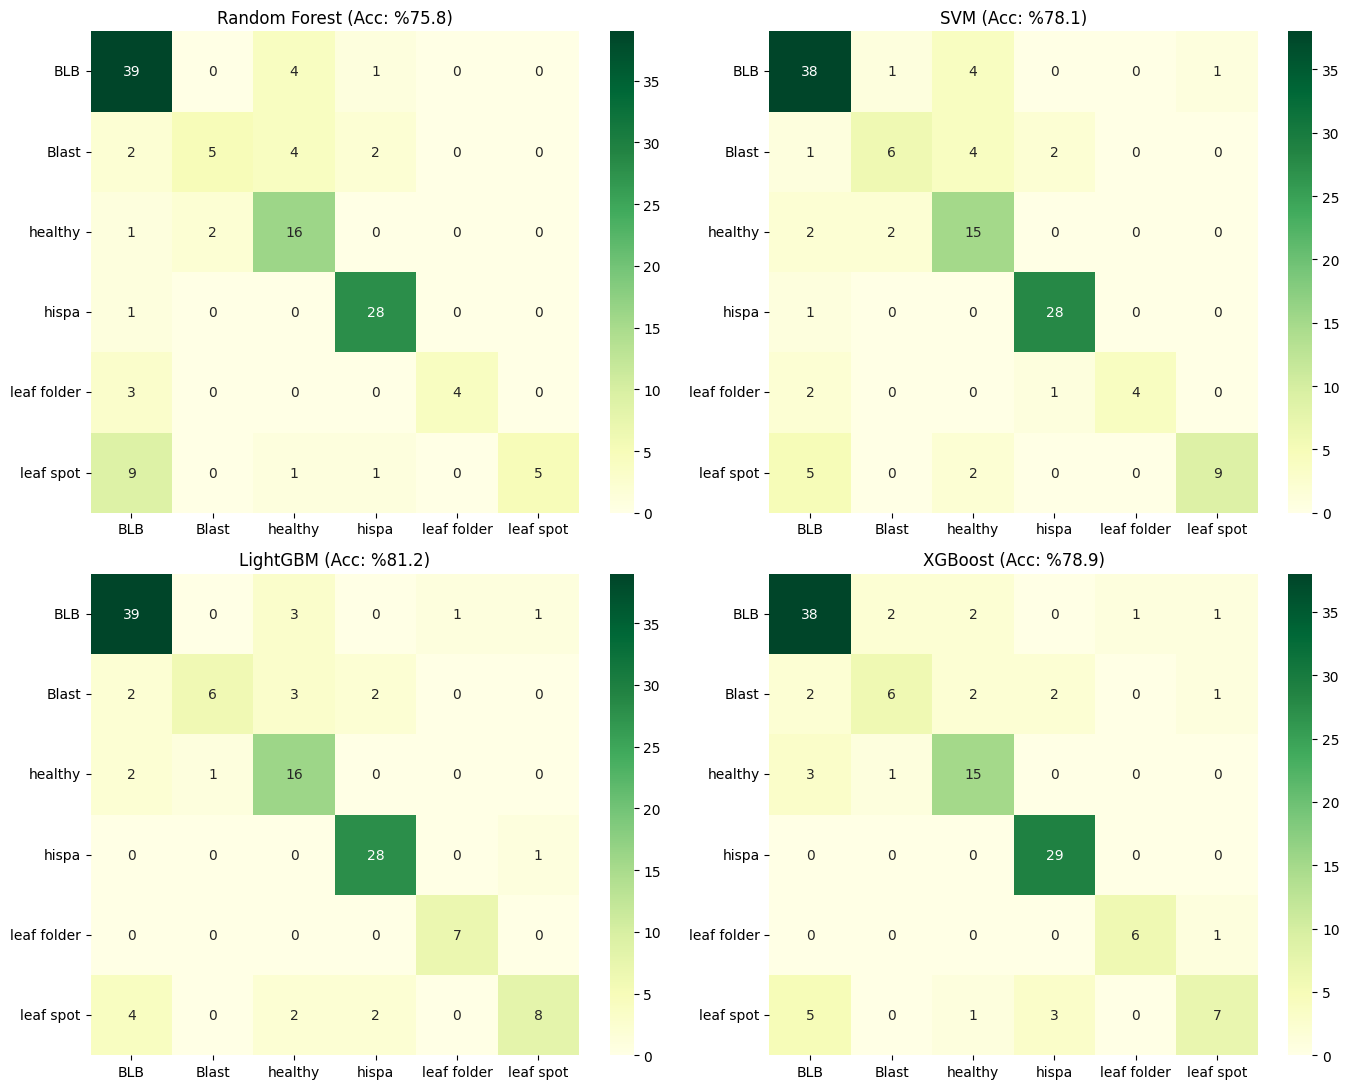

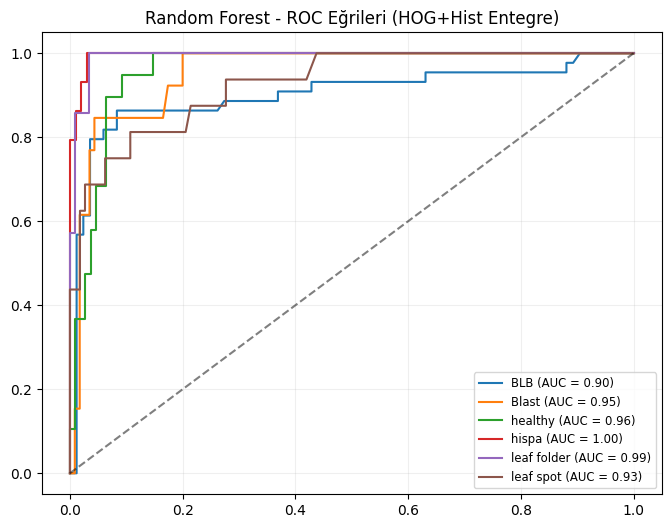

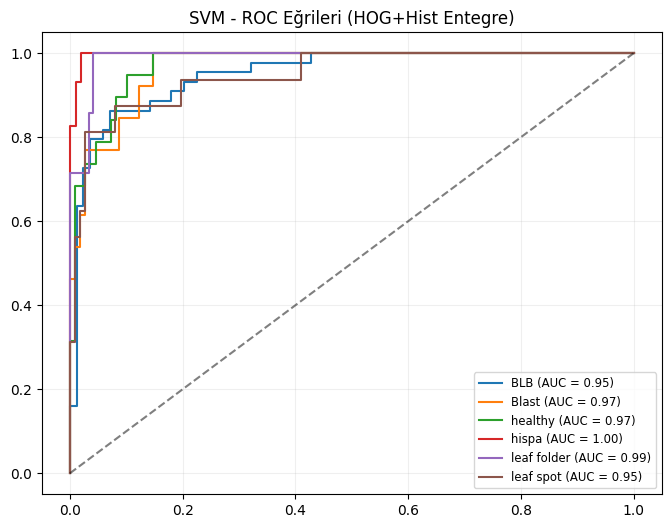

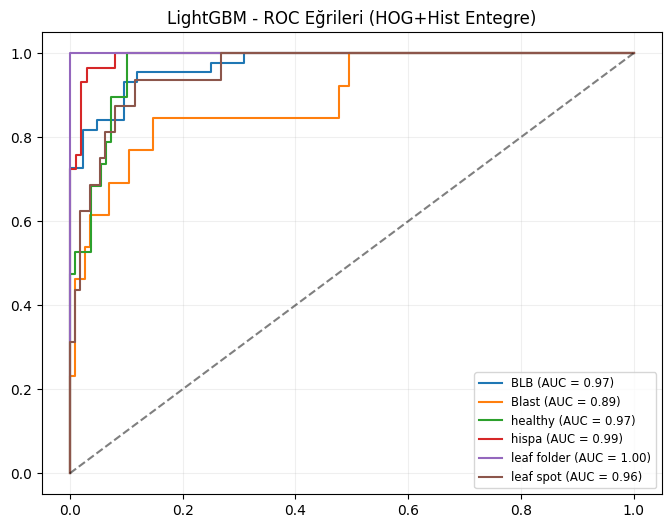

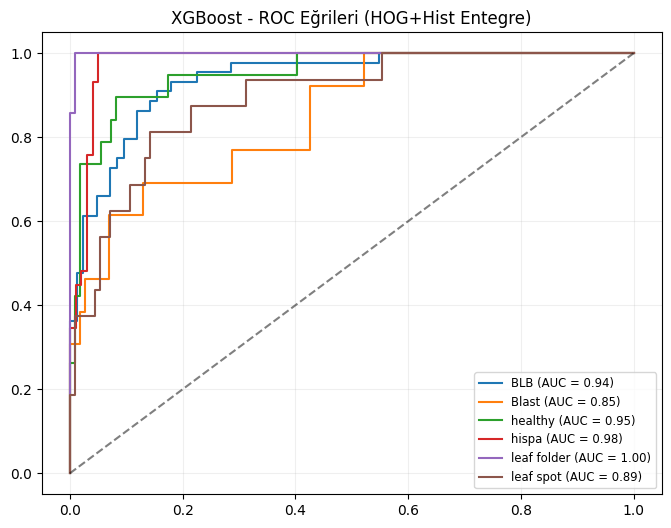

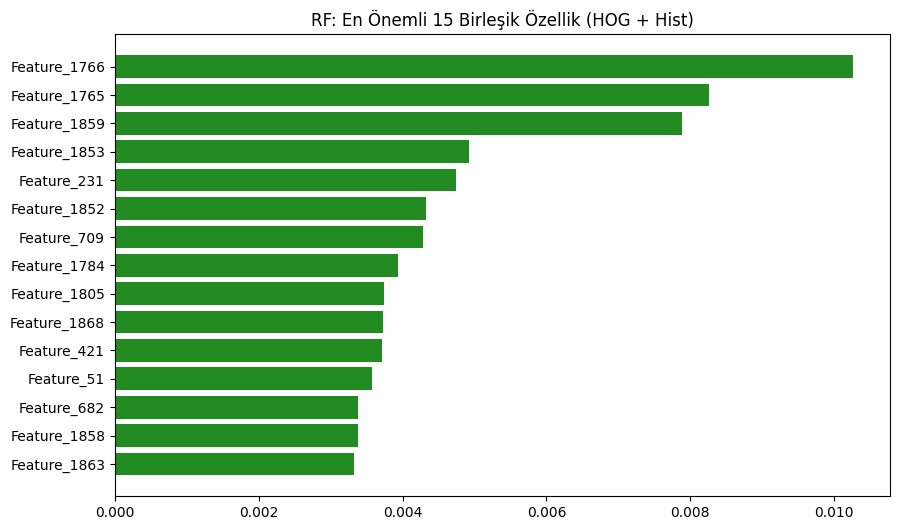


 GENEL MODEL KARŞILAŞTIRMA ÖZETİ
               Accuracy  W. Precision  W. Recall  W. F1-Score
Model                                                        
LightGBM          0.812         0.817      0.812        0.802
XGBoost           0.789         0.779      0.789        0.776
SVM               0.781         0.795      0.781        0.775
Random Forest     0.758         0.789      0.758        0.737


In [1]:
# --- 1. ADIM: KAGGLE API AYARLARI VE VERİ İNDİRME ---
from google.colab import files
import os

if not os.path.exists('/content/kaggle.json'):
    print("Lütfen kaggle.json dosyasını yükleyin...")
    files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/*.json

print("Veri seti indiriliyor...")
!kaggle datasets download -d sujaradha/thermal-images-diseased-healthy-leaves-paddy
!unzip -qo thermal-images-diseased-healthy-leaves-paddy.zip -d dataset
print("Veri hazır!")

# --- 2. ADIM: KÜTÜPHANELER VE ÖZELLİK ÇIKARIM FONKSİYONLARI ---
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score, precision_recall_fscore_support
from skimage.feature import local_binary_pattern


def extract_advanced_features(img_path):
    img = cv2.imread(img_path)
    if img is None: return None
    img = cv2.resize(img, (128, 128))

    # --- A. HSV HİSTOGRAMI (Termal Hassasiyet için) ---
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist_features = []
    for i in range(3):
        hist = cv2.calcHist([hsv], [i], None, [32], [0, 256])
        cv2.normalize(hist, hist)
        hist_features.extend(hist.flatten())

    # --- B. LBP (Doku Detayı için) ---
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    (lbp_hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, 11), range=(0, 10))
    lbp_hist = lbp_hist.astype("float")
    lbp_hist /= (lbp_hist.sum() + 1e-7) # Normalizasyon

    # --- C. HOG (Genel Şekil için) ---
    hog_feats = hog(gray, orientations=9, pixels_per_cell=(16, 16), # Daha hızlı eğitim için 16,16
                    cells_per_block=(2, 2), visualize=False)

    # Üçünü birleştir: Şekil + Doku + Hassas Renk
    return np.hstack([hog_feats, hist_features, lbp_hist])

def prepare_dataset(base_path):
    data = []
    labels = []
    print("Görseller işleniyor ve özellikler birleştiriliyor...")
    for category in os.listdir(base_path):
        cat_path = os.path.join(base_path, category)
        if os.path.isdir(cat_path):
            for img_name in os.listdir(cat_path):
                feat = extract_advanced_features(os.path.join(cat_path, img_name))
                if feat is not None:
                    data.append(feat)
                    labels.append(category)
    return np.array(data), np.array(labels)

# --- 3. ADIM: VERİ HAZIRLAMA VE ÖLÇEKLENDİRME ---
data_path = '/content/dataset/thermal images UL'
X, y = prepare_dataset(data_path)

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Stratify=y_encoded kullanarak sınıfların dengeli bölünmesini sağlıyoruz
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# StandardScaler: HOG ve Histogram değerlerini ortak bir ölçeğe taşır
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# --- 4. ADIM: MODELLERİN EĞİTİMİ ---
models = {
    "Random Forest": RandomForestClassifier(n_estimators=500, max_depth=20, random_state=42),
    "SVM": SVC(probability=True, kernel='rbf', C=50, gamma='auto', random_state=42), # C değeri artırıldı
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=64, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=7, learning_rate=0.03, random_state=42)
}

results = {}
for name, model in models.items():
    print(f"{name} eğitiliyor...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    results[name] = {"preds": y_pred, "probs": y_prob, "acc": accuracy_score(y_test, y_pred), "model": model}

# --- 5. ADIM: GÖRSELLEŞTİRME VE ANALİZ ---

# A. Confusion Matrix (YlGn)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()
for i, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res["preds"])
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGn', ax=axes[i],
                xticklabels=le.classes_, yticklabels=le.classes_)
    axes[i].set_title(f"{name} (Acc: %{res['acc']*100:.1f})")
plt.tight_layout()
plt.show()

# B. ROC Eğrileri (One-vs-Rest)
n_classes = len(le.classes_)
for name, res in results.items():
    plt.figure(figsize=(8, 6))
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test == i, res["probs"][:, i])
        plt.plot(fpr, tpr, label=f'{le.classes_[i]} (AUC = {auc(fpr, tpr):.2f})')
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    plt.title(f'{name} - ROC Eğrileri (HOG+Hist Entegre)')
    plt.legend(loc="lower right", fontsize='small')
    plt.grid(alpha=0.2)
    plt.show()

# C. Random Forest Özellik Önem Tablosu
rf_model = results["Random Forest"]["model"]
importances = rf_model.feature_importances_
top_indices = np.argsort(importances)[-15:]
plt.figure(figsize=(10, 6))
plt.title("RF: En Önemli 15 Birleşik Özellik (HOG + Hist)")
plt.barh(range(len(top_indices)), importances[top_indices], color='#228B22')
plt.yticks(range(len(top_indices)), [f"Feature_{i}" for i in top_indices])
plt.show()

# --- 6. ADIM: DETAYLI PERFORMANS TABLOLARI ---
summary_data = []
for name, res in results.items():
    p, r, f, s = precision_recall_fscore_support(y_test, res["preds"], average=None)
    for i, class_name in enumerate(le.classes_):
        summary_data.append({"Model": name, "Sınıf": class_name, "Precision": p[i], "Recall": r[i], "F1": f[i], "Acc": res["acc"]})

df_master = pd.DataFrame(summary_data)
print(f"\n{'='*65}\n GENEL MODEL KARŞILAŞTIRMA ÖZETİ\n{'='*65}")
summary_table = []
for name, res in results.items():
    p, r, f, _ = precision_recall_fscore_support(y_test, res["preds"], average='weighted')
    summary_table.append({"Model": name, "Accuracy": res["acc"], "W. Precision": p, "W. Recall": r, "W. F1-Score": f})

print(pd.DataFrame(summary_table).set_index("Model").sort_values(by="Accuracy", ascending=False).round(3))